# Project 2 – Logistic regression

## 1. Setup

In [1]:
%pip install lime shap umap-learn scikit-learn pandas numpy matplotlib seaborn scipy --quiet

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import warnings
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (log_loss, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, average_precision_score,
                             balanced_accuracy_score)
from sklearn.exceptions import ConvergenceWarning
import matplotlib.pyplot as plt
import seaborn as sns

# we deliberately run 1 iteration per call, so sklearn will warn every time - hide that
warnings.filterwarnings("ignore", category=ConvergenceWarning)

MODEL_TAG = 'LogReg'   # used in plot titles and file names

### Adjustable parameters

In [3]:
# split
test_size = 0.20          # 80/20 train/test
val_size = 0.20           # fraction of the TRAINING data used for validation (early stopping)
seed = 42
SEED = seed

# training
max_epochs = 100
C_reg = 1.0               # inverse regularization strength (smaller = stronger regularization)

# early stopping
patience = 5              # epochs without improvement before stopping
min_delta = 1e-5          # minimum decrease in val loss to count as an improvement

## 2. Data
### 2.1 Load data and make the binary target

In [4]:
# Load data
df = pd.read_csv("diabetes_012_health_indicators_BRFSS2015.csv")

print("Dataset shape:", df.shape)
print("\nOriginal 3-class label (0 = no diabetes, 1 = prediabetes, 2 = diabetes):")
print(df["Diabetes_012"].value_counts().sort_index())
df.head()

Dataset shape: (253680, 22)

Original 3-class label (0 = no diabetes, 1 = prediabetes, 2 = diabetes):
Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [5]:
# The task: does the person have prediabetes OR diabetes?  (Diabetes_012 = 1 or 2  ->  1)
df["Diabetes_binary"] = (df["Diabetes_012"] > 0).astype(int)

TARGET = "Diabetes_binary"
feature_names = [c for c in df.columns if c not in ["Diabetes_012", TARGET]]
FEATURE_COLS = feature_names
class_names = ['No diabetes', 'Prediabetes/Diabetes']
pos_label = 1          # index of the positive class

X = df[feature_names].values
y = df[TARGET].values.astype(int)
y012 = df["Diabetes_012"].values.astype(int)   # only used to colour the latent-space plots

print(f"X: {X.shape}, y: {y.shape}")
print(f"Classes (binary): {np.bincount(y)}")

X: (253680, 21), y: (253680,)
Classes (binary): [213703  39977]


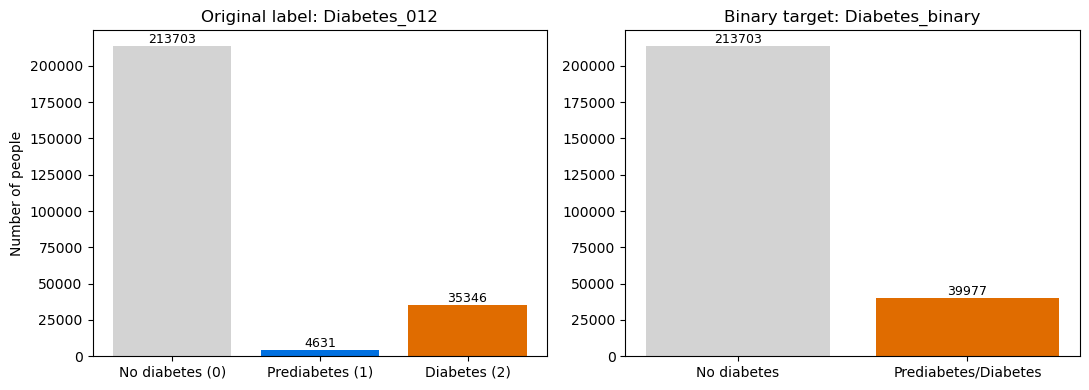

Share of positives (prediabetes or diabetes): 15.8%


In [6]:
# How imbalanced is the data?
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

counts_012 = df['Diabetes_012'].value_counts().sort_index()
axes[0].bar(['No diabetes (0)', 'Prediabetes (1)', 'Diabetes (2)'], counts_012.values,
            color=['lightgray', '#0070e0', '#e06c00'])
axes[0].set_title('Original label: Diabetes_012')
axes[0].set_ylabel('Number of people')

counts_bin = df[TARGET].value_counts().sort_index()
axes[1].bar(class_names, counts_bin.values, color=['lightgray', '#e06c00'])
axes[1].set_title(f'Binary target: {TARGET}')

for ax in axes:
    for p in ax.patches:
        ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

print(f'Share of positives (prediabetes or diabetes): {df[TARGET].mean():.1%}')

### 2.2 Train / validation / test split

In [7]:
# 80/20 split
X_train_raw, X_test_raw, y_train, y_test, y012_train, y012_test = train_test_split(
    X, y, y012, test_size=test_size, random_state=seed, stratify=y)

# validation set taken from the training data
X_train_raw, X_val_raw, y_train, y_val, y012_train, y012_val = train_test_split(
    X_train_raw, y_train, y012_train, test_size=val_size, random_state=seed, stratify=y_train)

print(f"Train: {X_train_raw.shape[0]}, Val: {X_val_raw.shape[0]}, Test: {X_test_raw.shape[0]}")
print(f"Share of positives  train: {y_train.mean():.3f}   val: {y_val.mean():.3f}   test: {y_test.mean():.3f}")

Train: 162355, Val: 40589, Test: 50736
Share of positives  train: 0.158   val: 0.158   test: 0.158


### 2.3 Standardization

In [8]:
train_mean = np.mean(X_train_raw, axis=0)
train_std = np.std(X_train_raw, axis=0)

X_train = (X_train_raw - train_mean) / train_std
X_val = (X_val_raw - train_mean) / train_std
X_test = (X_test_raw - train_mean) / train_std

print("Train mean:", np.round(np.mean(X_train, axis=0), 3))
print("Train std: ", np.round(np.std(X_train, axis=0), 3))

Train mean: [-0.  0. -0. -0.  0. -0. -0.  0. -0.  0. -0. -0. -0.  0. -0.  0.  0.  0.
  0.  0. -0.]
Train std:  [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### 2.4 Class weights

In [9]:
n_train = len(y_train)
n_neg = int(np.sum(y_train == 0))
n_pos = int(np.sum(y_train == 1))

w_neg = n_train / (2 * n_neg)
w_pos = n_train / (2 * n_pos)
class_weights = {0: w_neg, 1: w_pos}

# one weight per example (used for the weighted log loss)
sw_train = np.where(y_train == 1, w_pos, w_neg)
sw_val = np.where(y_val == 1, w_pos, w_neg)
sw_test = np.where(y_test == 1, w_pos, w_neg)

print(f'Negatives in train: {n_neg}  -> weight {w_neg:.3f}')
print(f'Positives in train: {n_pos}  -> weight {w_pos:.3f}')
print(f'Ratio w_pos / w_neg = {w_pos / w_neg:.3f}')

Negatives in train: 136769  -> weight 0.594
Positives in train: 25586  -> weight 3.173
Ratio w_pos / w_neg = 5.345


## 3. Training with early stopping

In [10]:
model = LogisticRegression(solver='lbfgs', max_iter=1, warm_start=True,
                           C=C_reg, class_weight=class_weights, random_state=seed)

train_losses = []
val_losses = []

best_val_loss = np.inf
best_coef = None
best_intercept = None
best_epoch = 0
epochs_without_improvement = 0

for epoch in range(max_epochs):
    # one epoch of training
    model.fit(X_train, y_train)

    # weighted loss on train and validation
    train_loss = log_loss(y_train, model.predict_proba(X_train), sample_weight=sw_train)
    val_loss = log_loss(y_val, model.predict_proba(X_val), sample_weight=sw_val)
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    # early stopping check
    if val_loss < best_val_loss - min_delta:
        best_val_loss = val_loss
        best_coef = model.coef_.copy()
        best_intercept = model.intercept_.copy()
        best_epoch = epoch
        epochs_without_improvement = 0
    else:
        epochs_without_improvement = epochs_without_improvement + 1

    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch}")
        break

# restore the best weights
model.coef_ = best_coef
model.intercept_ = best_intercept

print(f"Best epoch: {best_epoch}, val loss: {best_val_loss:.4f}")

Early stopping at epoch 16
Best epoch: 11, val loss: 0.5182


### 3.1 Testing

In [11]:
train_pred = model.predict(X_train)
val_pred = model.predict(X_val)
test_pred = model.predict(X_test)

train_acc = np.mean(train_pred == y_train)
val_acc = np.mean(val_pred == y_val)
test_acc = np.mean(test_pred == y_test)

print(f"Train accuracy: {train_acc:.3f}")
print(f"Val accuracy:   {val_acc:.3f}")
print(f"Test accuracy:  {test_acc:.3f}")

Train accuracy: 0.729
Val accuracy:   0.730
Test accuracy:  0.731


Test accuracy:          0.731
Test balanced accuracy: 0.743
ROC-AUC:                0.818
PR-AUC (avg precision): 0.433   (random model = 0.158)

                      precision    recall  f1-score   support

         No diabetes      0.942     0.725     0.819     42741
Prediabetes/Diabetes      0.341     0.761     0.471      7995

            accuracy                          0.731     50736
           macro avg      0.641     0.743     0.645     50736
        weighted avg      0.847     0.731     0.764     50736



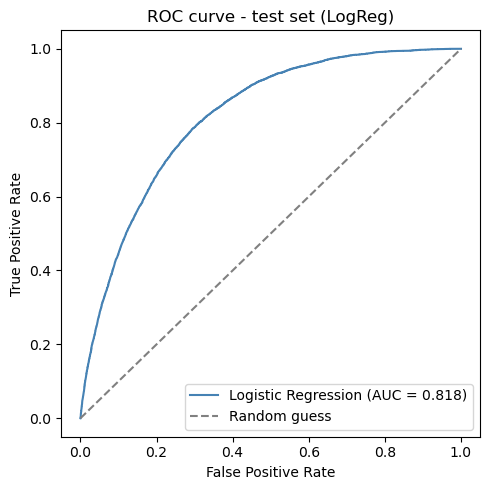

In [12]:
# Probabilities for the positive class, for ROC-AUC and PR-AUC
test_proba = model.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, test_proba)
test_ap = average_precision_score(y_test, test_proba)
test_bal_acc = balanced_accuracy_score(y_test, test_pred)

print(f"Test accuracy:          {test_acc:.3f}")
print(f"Test balanced accuracy: {test_bal_acc:.3f}")
print(f"ROC-AUC:                {test_auc:.3f}")
print(f"PR-AUC (avg precision): {test_ap:.3f}   (random model = {y_test.mean():.3f})\n")
print(classification_report(y_test, test_pred, target_names=class_names, digits=3))

fpr, tpr, _ = roc_curve(y_test, test_proba)

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {test_auc:.3f})', color='steelblue')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curve - test set (LogReg)')
plt.legend()
plt.tight_layout()
plt.show()

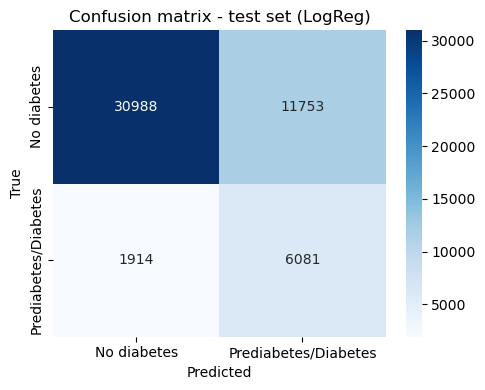

In [13]:
# Confusion matrix on the test set
cm = confusion_matrix(y_test, test_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion matrix - test set (LogReg)')
plt.tight_layout()
plt.show()

In [14]:
# Recall split by the ORIGINAL label: how many prediabetes vs diabetes cases does the model catch?
for c, name in [(1, 'Prediabetes (1)'), (2, 'Diabetes (2)')]:
    mask = y012_test == c
    recall_c = np.mean(test_pred[mask] == 1)
    print(f'{name:16s}: {mask.sum():5d} people in test set, caught {recall_c:.1%}')

Prediabetes (1) :   906 people in test set, caught 61.4%
Diabetes (2)    :  7089 people in test set, caught 77.9%


### 3.2 Loss evaluation

In [15]:
# final (class-weighted) loss on each set, with the best weights
final_train_loss = log_loss(y_train, model.predict_proba(X_train), sample_weight=sw_train)
final_val_loss = log_loss(y_val, model.predict_proba(X_val), sample_weight=sw_val)
final_test_loss = log_loss(y_test, model.predict_proba(X_test), sample_weight=sw_test)

print(f"Train loss: {final_train_loss:.4f}")
print(f"Val loss:   {final_val_loss:.4f}")
print(f"Test loss:  {final_test_loss:.4f}")

Train loss: 0.5220
Val loss:   0.5182
Test loss:  0.5215


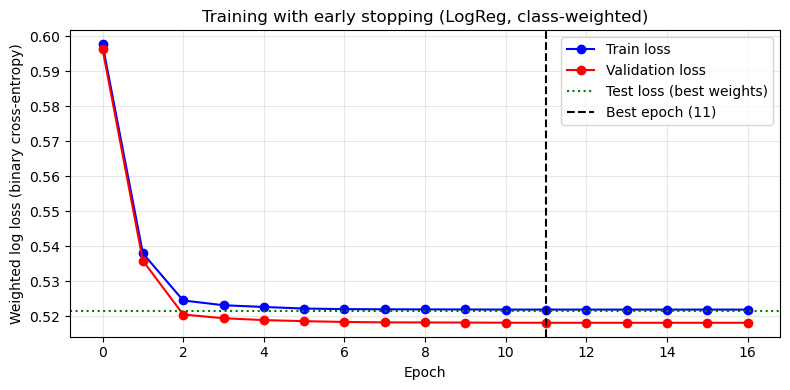

In [16]:
# Loss curves
epochs = np.arange(len(train_losses))

plt.figure(figsize=(8, 4))
plt.plot(epochs, train_losses, 'o-', label='Train loss', color='blue')
plt.plot(epochs, val_losses, 'o-', label='Validation loss', color='red')
plt.axhline(final_test_loss, color='green', linestyle=':', label='Test loss (best weights)')
plt.axvline(best_epoch, color='black', linestyle='--', label=f'Best epoch ({best_epoch})')
plt.xlabel('Epoch')
plt.ylabel('Weighted log loss (binary cross-entropy)')
plt.title('Training with early stopping (LogReg, class-weighted)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Prediction functions for explainability

In [17]:
# Binary (0/1) features are treated as categorical by LIME; ordinal features (Age, GenHlth, ...) stay numeric
cat_cols = [c for c in FEATURE_COLS
            if set(np.unique(X_train_raw[:, FEATURE_COLS.index(c)])) <= {0, 1}]
num_cols = [c for c in FEATURE_COLS if c not in cat_cols]
cat_indices = [FEATURE_COLS.index(c) for c in cat_cols]

print('Categorical (binary):', cat_cols)
print('Numerical / ordinal :', num_cols)

Categorical (binary): ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']
Numerical / ordinal : ['BMI', 'GenHlth', 'MentHlth', 'PhysHlth', 'Age', 'Education', 'Income']


In [18]:
# Prediction functions on UNSCALED data (standardization is applied inside)
def predict_proba(X_raw_array):
    X_scaled = (np.asarray(X_raw_array, dtype=float) - train_mean) / train_std
    return model.predict_proba(X_scaled)

def predict(X_raw_array):
    return (predict_proba(X_raw_array)[:, 1] >= 0.5).astype(int)

# Sanity check: must give the same predictions as the model on the scaled test set
assert np.allclose(predict_proba(X_test_raw), model.predict_proba(X_test))
test_pred = predict(X_test_raw)
print(f'Test accuracy: {np.mean(test_pred == y_test):.3f}')

Test accuracy: 0.731


## 4. LIME explainer

In [19]:
import lime
import lime.lime_tabular

# Readable names for the binary features (0 = No, 1 = Yes; for Sex: 0 = female, 1 = male)
categorical_names = {}
for col in cat_cols:
    col_idx = FEATURE_COLS.index(col)
    if col == 'Sex':
        categorical_names[col_idx] = ['Female', 'Male']
    else:
        categorical_names[col_idx] = ['No', 'Yes']

explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_raw,
    feature_names=FEATURE_COLS,
    class_names=class_names,
    categorical_features=cat_indices,
    categorical_names=categorical_names,
    mode='classification',
    random_state=42,
)
print('Explainer ready.')

Explainer ready.


## 5. LIME: single prediction

In [20]:
# Pick the first test instance predicted as positive (prediabetes/diabetes)
diabetes_mask = test_pred == pos_label
idx = np.where(diabetes_mask)[0][0]

instance = X_test_raw[idx]
pred_proba = predict_proba(instance.reshape(1, -1))[0]
pred_class = class_names[int(pred_proba.argmax())]

print(f'Explaining instance index {idx}')
print(f'Predicted class : {pred_class}   (true class: {class_names[int(y_test[idx])]}, Diabetes_012 = {y012_test[idx]})')
print(f'Class probabilities: {dict(zip(class_names, pred_proba.round(3)))}')
pd.Series(instance, index=FEATURE_COLS).to_frame('value').T

Explaining instance index 0
Predicted class : Prediabetes/Diabetes   (true class: No diabetes, Diabetes_012 = 0)
Class probabilities: {'No diabetes': np.float64(0.43), 'Prediabetes/Diabetes': np.float64(0.57)}


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
value,1.0,0.0,1.0,31.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,0.0,9.0,4.0,5.0


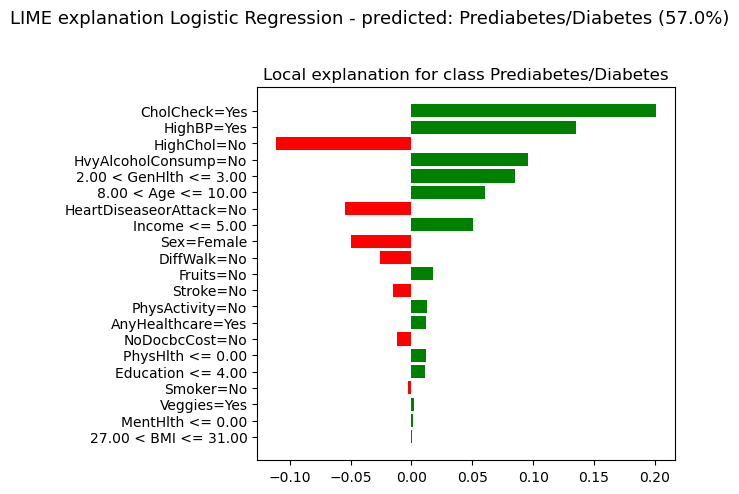

In [21]:
exp = explainer.explain_instance(
    data_row=instance,
    predict_fn=predict_proba,
    num_features=len(FEATURE_COLS),   # all 21 features in the explanation
    num_samples=5000,                 # neighbourhood samples for the surrogate
)

fig = exp.as_pyplot_figure(label=pos_label)
fig.suptitle(f'LIME explanation Logistic Regression - predicted: {pred_class} ({pred_proba.max():.1%})',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [22]:
# Also inspect the raw weights as a DataFrame
weights = exp.as_list(label=pos_label)
pd.DataFrame(weights, columns=['feature condition', 'LIME weight']).sort_values(
    'LIME weight', key=abs, ascending=False
)

,feature condition,LIME weight
0,CholCheck=Yes,0.200693
1,HighBP=Yes,0.135515
2,HighChol=No,-0.111173
3,HvyAlcoholConsump=No,0.095583
4,2.00 < GenHlth <= 3.00,0.085184
5,8.00 < Age <= 10.00,0.060591
6,HeartDiseaseorAttack=No,-0.054475
7,Income <= 5.00,0.050927
8,Sex=Female,-0.049297
9,DiffWalk=No,-0.025867


## 6. LIME: no-diabetes prediction

Explaining instance index 14 (true class: No diabetes)


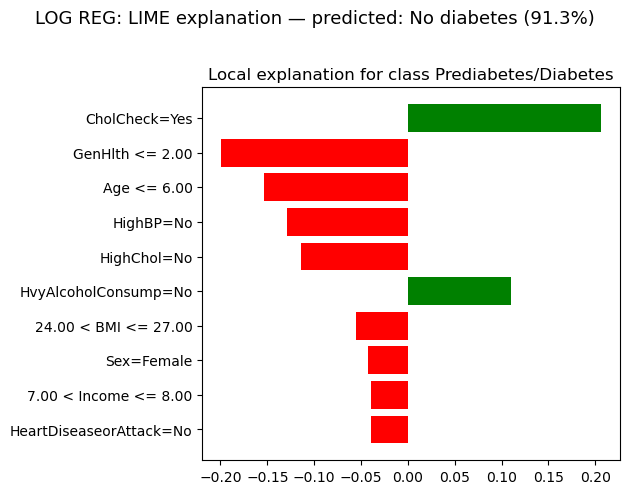

In [23]:
no_diabetes_mask = test_pred == 0
idx2 = np.where(no_diabetes_mask)[0][12]

instance2 = X_test_raw[idx2]
pred_proba2 = predict_proba(instance2.reshape(1, -1))[0]
pred_class2 = class_names[int(pred_proba2.argmax())]

exp2 = explainer.explain_instance(
    data_row=instance2,
    predict_fn=predict_proba,
    num_features=10,
    num_samples=5000,
)

print(f'Explaining instance index {idx2} (true class: {class_names[int(y_test[idx2])]})')
fig2 = exp2.as_pyplot_figure(label=pos_label)
fig2.suptitle(f'LOG REG: LIME explanation — predicted: {pred_class2} ({pred_proba2.max():.1%})',
              fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [24]:
# How well does LIME's local surrogate fit the model for this instance?
r2 = exp2.score
if isinstance(r2, dict):          # newer LIME versions store it per class
    r2 = r2[pos_label]

local_pred = exp2.local_pred
if isinstance(local_pred, dict):
    local_pred = local_pred[pos_label]
local_pred = float(np.ravel(local_pred)[0])

print(f"LIME R^2:              {r2:.3f}")
print(f"LIME local prediction: {local_pred:.3f}")
print(f"Model prediction:      {pred_proba2[pos_label]:.3f}")

LIME R^2:              0.608
LIME local prediction: -0.007
Model prediction:      0.087


## 7. LIME: stability across seeds

In [25]:
from collections import Counter

N_RUNS = 10
top_k = 5

feature_counts = Counter()
for run_seed in range(N_RUNS):
    local_exp = lime.lime_tabular.LimeTabularExplainer(
        training_data=X_train_raw,
        feature_names=FEATURE_COLS,
        class_names=class_names,
        categorical_features=cat_indices,
        categorical_names=categorical_names,
        mode='classification',
        random_state=run_seed,
    ).explain_instance(
        data_row=instance,
        predict_fn=predict_proba,
        num_features=top_k,
        num_samples=5000,
    )
    for feat_name, _ in local_exp.as_list(label=pos_label):
        feature_counts[feat_name] += 1

stability_df = pd.DataFrame(
    feature_counts.most_common(), columns=['feature condition', f'appearances (/{N_RUNS})']
)
print(stability_df.to_string(index=False))

     feature condition  appearances (/10)
         CholCheck=Yes                 10
            HighBP=Yes                 10
           HighChol=No                 10
2.00 < GenHlth <= 3.00                 10
  HvyAlcoholConsump=No                  3
        Income <= 5.00                  3
            Sex=Female                  2
   8.00 < Age <= 10.00                  2


## 8. LIME: aggregated weights (global view)

In [26]:
N_EXPLAIN = 100  # increase for smoother averages (slower)
rng = np.random.default_rng(0)
sample_idx = rng.choice(len(X_test_raw), size=N_EXPLAIN, replace=False)

weight_accumulator = {f: [] for f in FEATURE_COLS}

for i in sample_idx:
    e = explainer.explain_instance(
        data_row=X_test_raw[i],
        predict_fn=predict_proba,
        num_features=len(FEATURE_COLS),
        num_samples=1000,   # fewer samples: faster but noisier
    )
    for feat_idx, w in e.as_map()[pos_label]:
        weight_accumulator[FEATURE_COLS[feat_idx]].append(w)

mean_abs_weight = {}
for f, ws in weight_accumulator.items():
    if ws:
        mean_abs_weight[f] = np.mean(np.abs(ws))

global_df = pd.DataFrame(
    sorted(mean_abs_weight.items(), key=lambda x: x[1], reverse=True),
    columns=['feature', 'mean |LIME weight|']
)
print(global_df.to_string(index=False))

             feature  mean |LIME weight|
           CholCheck            0.190534
             GenHlth            0.175675
              HighBP            0.130980
            HighChol            0.112318
   HvyAlcoholConsump            0.108869
                 BMI            0.105601
                 Age            0.099107
                 Sex            0.044882
HeartDiseaseorAttack            0.042695
              Income            0.035281
              Stroke            0.024286
         NoDocbcCost            0.019346
            DiffWalk            0.016978
       AnyHealthcare            0.016659
           Education            0.013175
            PhysHlth            0.013157
             Veggies            0.010975
              Fruits            0.010814
        PhysActivity            0.009629
            MentHlth            0.008094
              Smoker            0.006598


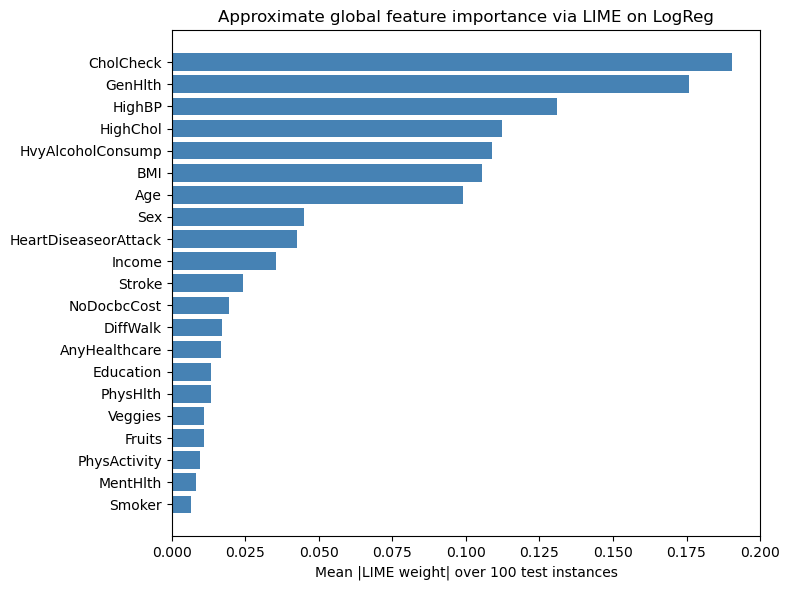

In [27]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(global_df['feature'][::-1], global_df['mean |LIME weight|'][::-1], color='steelblue')
ax.set_xlabel(f'Mean |LIME weight| over {N_EXPLAIN} test instances')
ax.set_title('Approximate global feature importance via LIME on LogReg')
plt.tight_layout()
plt.show()

## 9. SHAP (LinearExplainer)

In [28]:
import shap

# SHAP for logistic regression: LinearExplainer (exact, deterministic, fast)
N_BACKGROUND = 200
rng_bg = np.random.default_rng(SEED)
bg_idx = rng_bg.choice(len(X_train), size=N_BACKGROUND, replace=False)
background = X_train[bg_idx]      # scaled data, like the model was trained on

lin_explainer = shap.LinearExplainer(
    model, shap.maskers.Independent(background, max_samples=N_BACKGROUND)
)

N_SHAP = 500
sv_pos_all = lin_explainer.shap_values(X_test[:N_SHAP])          # (N_SHAP, n_features)
expected_val = float(np.ravel(lin_explainer.expected_value)[0])

# Efficiency check: baseline + sum of SHAP values = log-odds (decision_function), NOT probability
reconstructed = expected_val + sv_pos_all.sum(axis=1)
print(f'SHAP values shape : {sv_pos_all.shape}')
print(f'Baseline (log-odds): {expected_val:.4f}')
print(f'Max |f(x) − (E[f(X)] + Σ SHAP)|: {np.max(np.abs(model.decision_function(X_test[:N_SHAP]) - reconstructed)):.2e}')

SHAP values shape : (500, 21)
Baseline (log-odds): -0.7416
Max |f(x) − (E[f(X)] + Σ SHAP)|: 1.33e-15


### 9.1 SHAP: single instances

Instance predicted as: Prediabetes/Diabetes (57.0%)


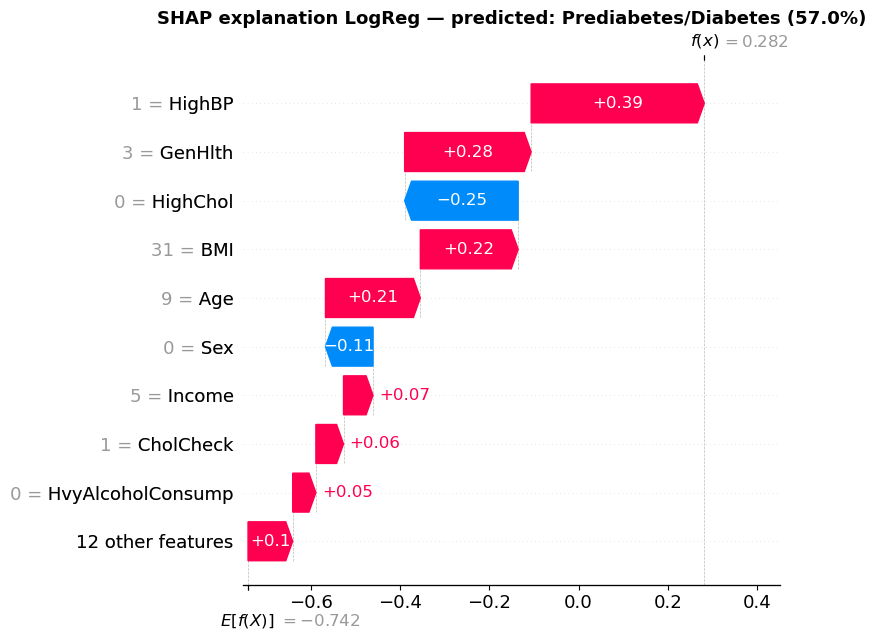

In [29]:
sv_hi_pos = lin_explainer.shap_values(X_test[idx:idx + 1])[0]        # log-odds contributions

shap_exp_hi = shap.Explanation(
    values=sv_hi_pos,
    base_values=expected_val,
    data=instance,
    feature_names=FEATURE_COLS,
)
print(f'Instance predicted as: {pred_class} ({pred_proba.max():.1%})')
shap.plots.waterfall(shap_exp_hi, show=False)
plt.title(f'SHAP explanation LogReg — predicted: {pred_class} ({pred_proba.max():.1%})',
          fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

Instance predicted as: No diabetes (91.3%)


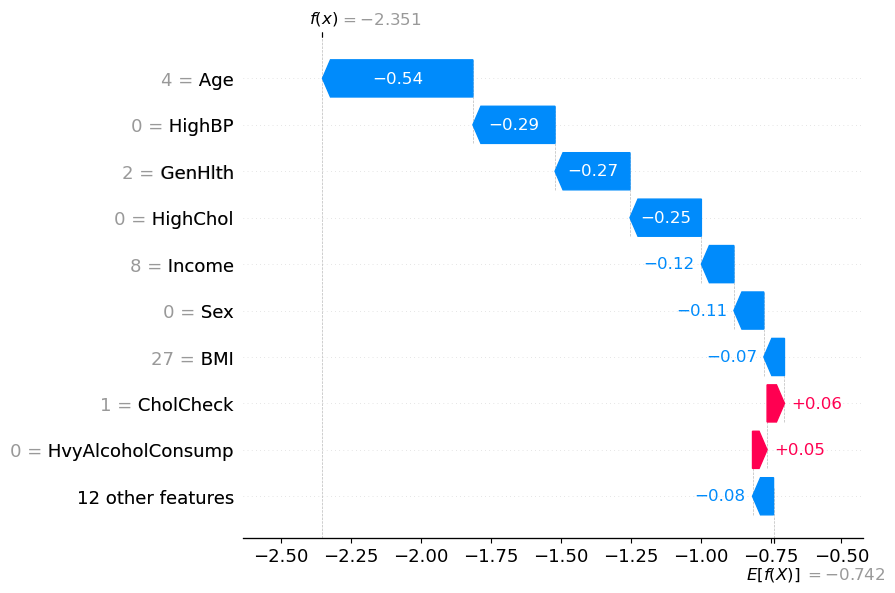

In [30]:
sv_lo_pos = lin_explainer.shap_values(X_test[idx2:idx2 + 1])[0]

shap_exp_lo = shap.Explanation(
    values=sv_lo_pos,
    base_values=expected_val,
    data=instance2,
    feature_names=FEATURE_COLS,
)
print(f'Instance predicted as: {pred_class2} ({pred_proba2.max():.1%})')
shap.plots.waterfall(shap_exp_lo)

### 9.2 SHAP: global importance

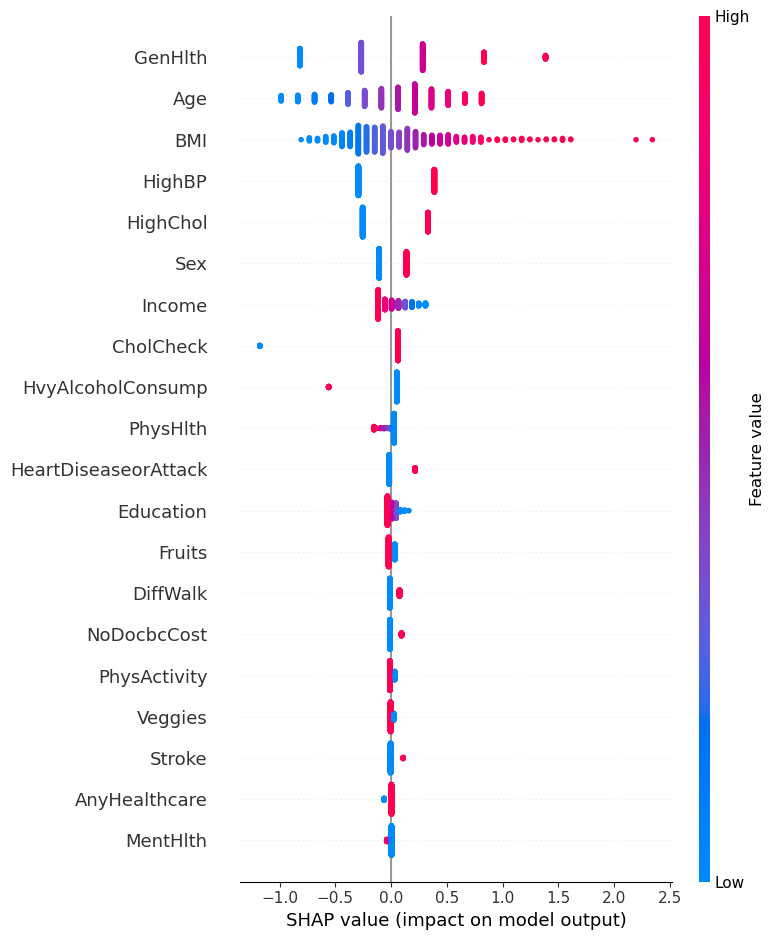

In [31]:
shap.summary_plot(sv_pos_all, X_test_raw[:N_SHAP], feature_names=FEATURE_COLS)

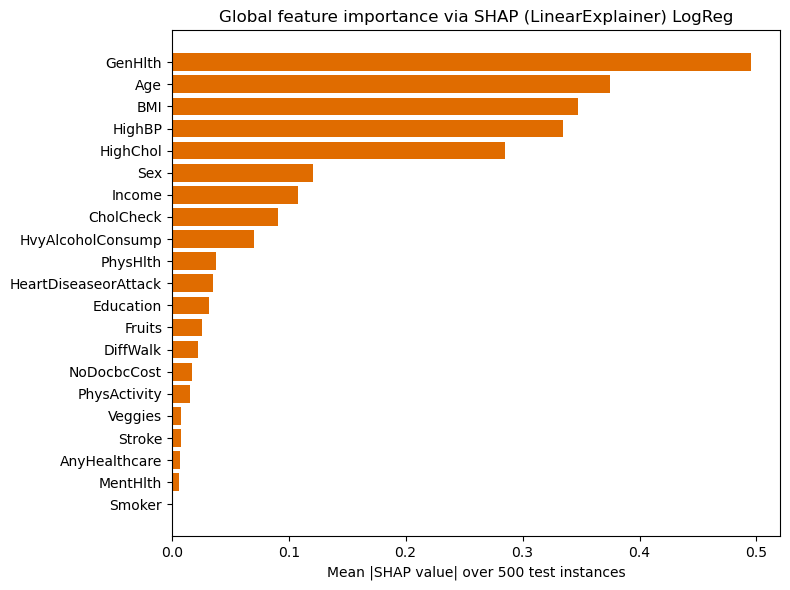

             feature  mean |SHAP|
             GenHlth     0.495391
                 Age     0.374829
                 BMI     0.347295
              HighBP     0.334574
            HighChol     0.284985
                 Sex     0.120795
              Income     0.108047
           CholCheck     0.091018
   HvyAlcoholConsump     0.070306
            PhysHlth     0.037389
HeartDiseaseorAttack     0.035316
           Education     0.032181
              Fruits     0.026024
            DiffWalk     0.022422
         NoDocbcCost     0.017087
        PhysActivity     0.015522
             Veggies     0.007725
              Stroke     0.007709
       AnyHealthcare     0.007225
            MentHlth     0.006408
              Smoker     0.000228


In [32]:
mean_abs_shap = np.mean(np.abs(sv_pos_all), axis=0)
shap_global_df = pd.DataFrame({
    'feature': FEATURE_COLS,
    'mean |SHAP|': mean_abs_shap,
}).sort_values('mean |SHAP|', ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(shap_global_df['feature'][::-1], shap_global_df['mean |SHAP|'][::-1], color='#e06c00')
ax.set_xlabel(f'Mean |SHAP value| over {N_SHAP} test instances')
ax.set_title('Global feature importance via SHAP (LinearExplainer) LogReg')
plt.tight_layout()
plt.show()
print(shap_global_df.to_string(index=False))

## 10. LIME vs SHAP
### 10.1 Same instance

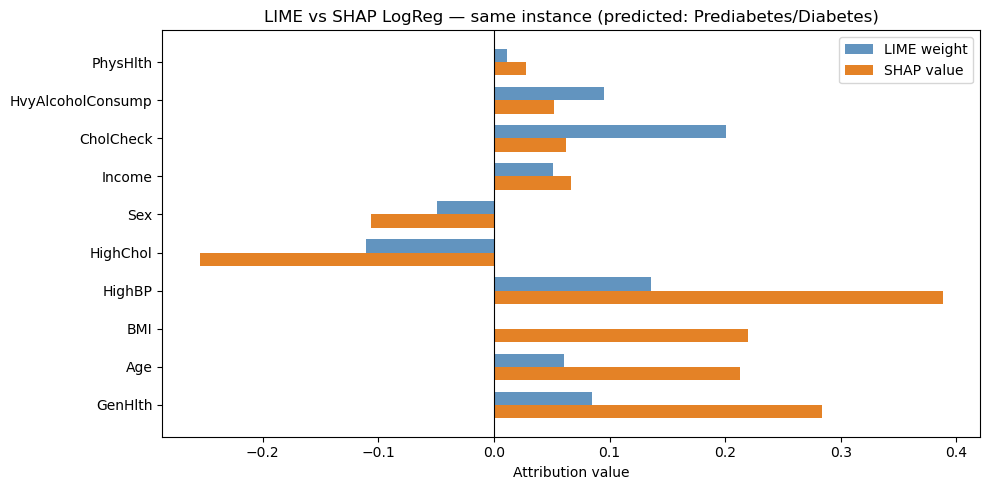

In [33]:
# LIME weights for the positive instance -> map to feature names
lime_by_feature = {FEATURE_COLS[i]: w for i, w in exp.as_map()[pos_label]}

# SHAP values for the same instance
shap_by_feature = dict(zip(FEATURE_COLS, sv_hi_pos))

# Compare over the top-10 features by mean |SHAP| (global ranking)
top10 = shap_global_df['feature'].head(10).tolist()
lime_local = [lime_by_feature.get(f, 0) for f in top10]
shap_local = [shap_by_feature[f] for f in top10]

x = np.arange(len(top10))
bar_w = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(x + bar_w/2, lime_local, bar_w, label='LIME weight', color='steelblue', alpha=0.85)
ax.barh(x - bar_w/2, shap_local, bar_w, label='SHAP value', color='#e06c00', alpha=0.85)
ax.set_yticks(x)
ax.set_yticklabels(top10)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Attribution value')
ax.set_title(f'LIME vs SHAP LogReg — same instance (predicted: {pred_class})')
ax.legend()
plt.tight_layout()
plt.show()

### 10.2 Global ranking

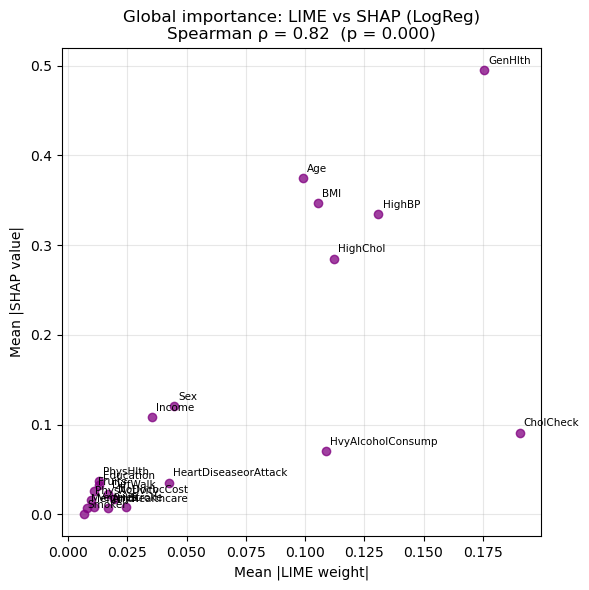

Spearman rank correlation: ρ = 0.817,  p = 0.0000


In [34]:
from scipy.stats import spearmanr

# Align global rankings by feature name
lime_series = global_df.set_index('feature')['mean |LIME weight|']
shap_series = shap_global_df.set_index('feature')['mean |SHAP|']
aligned = pd.DataFrame({'LIME': lime_series, 'SHAP': shap_series}).dropna()

rho, pval = spearmanr(aligned['LIME'], aligned['SHAP'])

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(aligned['LIME'], aligned['SHAP'], color='purple', alpha=0.75, zorder=3)
for feat, row in aligned.iterrows():
    ax.annotate(feat, (row['LIME'], row['SHAP']), fontsize=7.5, ha='left', va='bottom',
                xytext=(3, 3), textcoords='offset points')
ax.set_xlabel('Mean |LIME weight|')
ax.set_ylabel('Mean |SHAP value|')
ax.set_title(f'Global importance: LIME vs SHAP ({MODEL_TAG})\nSpearman ρ = {rho:.2f}  (p = {pval:.3f})')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print(f'Spearman rank correlation: ρ = {rho:.3f},  p = {pval:.4f}')

### 10.3 Fidelity

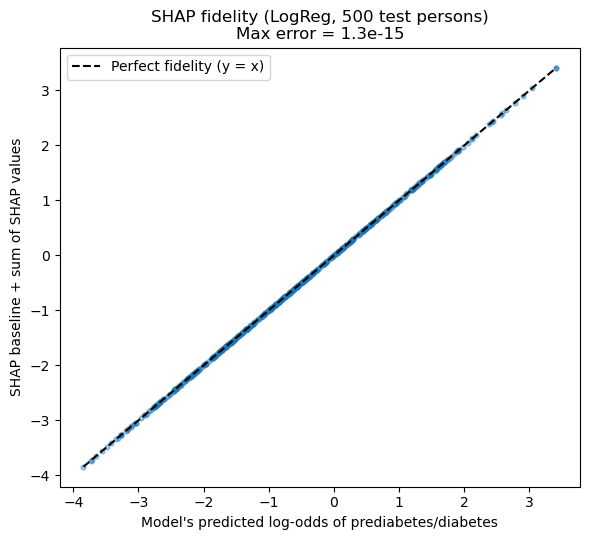

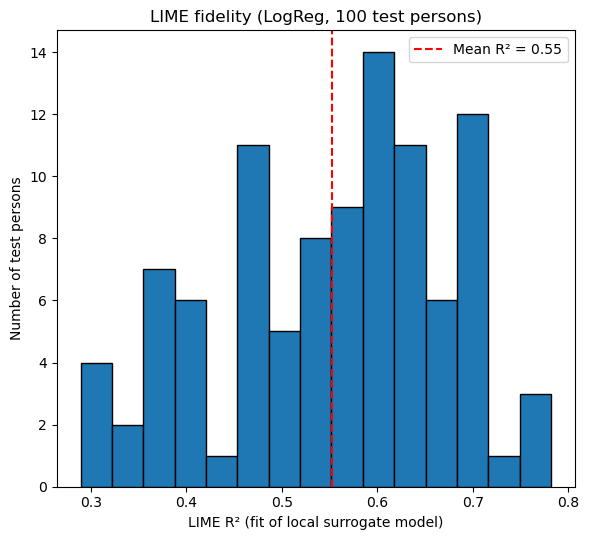

SHAP max error: 1.3e-15
LIME mean R²:   0.55  (min 0.29, max 0.78)


In [35]:
# ===== Fidelity: SHAP vs LIME (Logistic Regression) =====

# --- Plot 1: SHAP additivity (LinearExplainer explains log-odds) ---
f_x_logodds = model.decision_function(X_test[:N_SHAP])
max_err = np.max(np.abs(f_x_logodds - reconstructed))

lo = min(f_x_logodds.min(), reconstructed.min())
hi = max(f_x_logodds.max(), reconstructed.max())

plt.figure(figsize=(6, 5.5))
plt.scatter(f_x_logodds, reconstructed, alpha=0.4, s=12)
plt.plot([lo, hi], [lo, hi], 'k--', label='Perfect fidelity (y = x)')
plt.xlabel("Model's predicted log-odds of prediabetes/diabetes")
plt.ylabel('SHAP baseline + sum of SHAP values')
plt.title(f'SHAP fidelity (LogReg, {N_SHAP} test persons)\nMax error = {max_err:.1e}')
plt.legend()
plt.tight_layout()
plt.savefig('fidelity_shap_logreg.png', dpi=200)
plt.show()

# --- Plot 2: LIME R² across test persons ---
lime_r2 = []
for i in sample_idx:                  # same 100 test persons as section 8
    e = explainer.explain_instance(
        data_row=X_test_raw[i],
        predict_fn=predict_proba,
        num_features=len(FEATURE_COLS),
        num_samples=5000,
    )
    lime_r2.append(e.score)           # R² of LIME's local linear model

lime_r2 = np.array(lime_r2)

plt.figure(figsize=(6, 5.5))
plt.hist(lime_r2, bins=15, edgecolor='black')
plt.axvline(lime_r2.mean(), color='red', linestyle='--',
            label=f'Mean R² = {lime_r2.mean():.2f}')
plt.xlabel('LIME R² (fit of local surrogate model)')
plt.ylabel('Number of test persons')
plt.title(f'LIME fidelity (LogReg, {len(lime_r2)} test persons)')
plt.legend()
plt.tight_layout()
plt.savefig('fidelity_lime_logreg.png', dpi=200)
plt.show()

print(f'SHAP max error: {max_err:.1e}')
print(f'LIME mean R²:   {lime_r2.mean():.2f}  (min {lime_r2.min():.2f}, max {lime_r2.max():.2f})')

### 10.4 Model weights

Intercept: -0.587

             feature  coef (per 1 SD)  odds ratio (per 1 SD)  odds ratio (per unit)
             GenHlth            0.588                  1.801                  1.735
                 BMI            0.484                  1.623                  1.076
                 Age            0.458                  1.581                  1.162
              HighBP            0.337                  1.401                  1.977
            HighChol            0.289                  1.336                  1.796
           CholCheck            0.236                  1.266                  3.456
   HvyAlcoholConsump           -0.141                  0.869                  0.542
              Income           -0.126                  0.882                  0.941
                 Sex            0.122                  1.129                  1.278
HeartDiseaseorAttack            0.068                  1.070                  1.260
            PhysHlth           -0.053                  0.

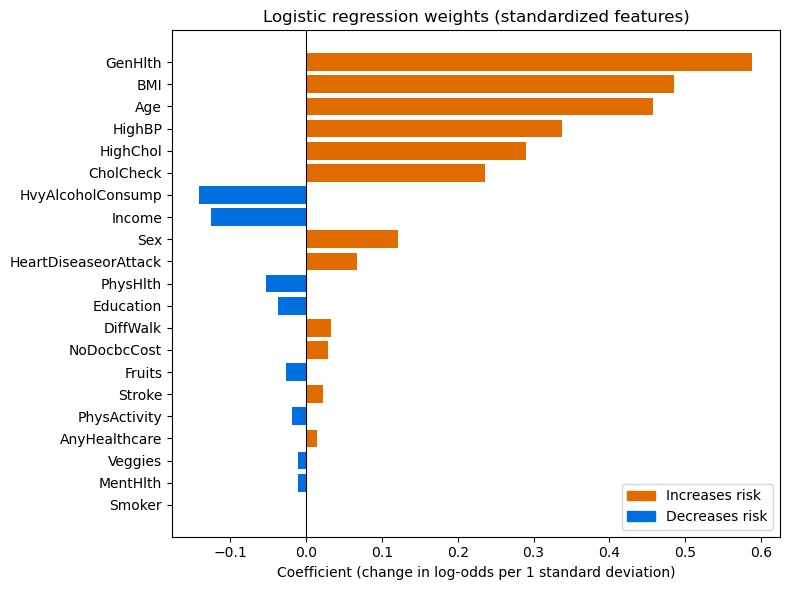

In [36]:
from matplotlib.patches import Patch

coefs = model.coef_[0]
intercept = model.intercept_[0]
stds = np.ravel(train_std)

coef_df = pd.DataFrame({
    'feature': FEATURE_COLS,
    'coef (per 1 SD)': coefs,
    'odds ratio (per 1 SD)': np.exp(coefs),
    'odds ratio (per unit)': np.exp(coefs / stds),
}).sort_values('coef (per 1 SD)', key=abs, ascending=False).reset_index(drop=True)

print(f'Intercept: {intercept:.3f}\n')
print(coef_df.round(3).to_string(index=False))

# Plot: largest weights at the top
plot_df = coef_df.iloc[::-1]
colors = ['#e06c00' if c > 0 else '#0070e0' for c in plot_df['coef (per 1 SD)']]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(plot_df['feature'], plot_df['coef (per 1 SD)'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Coefficient (change in log-odds per 1 standard deviation)')
ax.set_title('Logistic regression weights (standardized features)')
ax.legend(handles=[Patch(color='#e06c00', label='Increases risk'),
                   Patch(color='#0070e0', label='Decreases risk')],
          loc='lower right')
plt.tight_layout()
plt.savefig('logreg_weights.png', dpi=200)
plt.show()

### 10.5 False negative vs true positive

People with prediabetes/diabetes in test set: 7995
  Found (true positives):   6081
  Missed (false negatives): 1914

                      False negative (#22542)  True positive (#19770)
HighBP                                    0.0                     1.0
HighChol                                  0.0                     1.0
CholCheck                                 1.0                     1.0
BMI                                      20.0                    38.0
Smoker                                    0.0                     0.0
Stroke                                    0.0                     0.0
HeartDiseaseorAttack                      0.0                     0.0
PhysActivity                              1.0                     0.0
Fruits                                    1.0                     0.0
Veggies                                   1.0                     1.0
HvyAlcoholConsump                         0.0                     0.0
AnyHealthcare                             

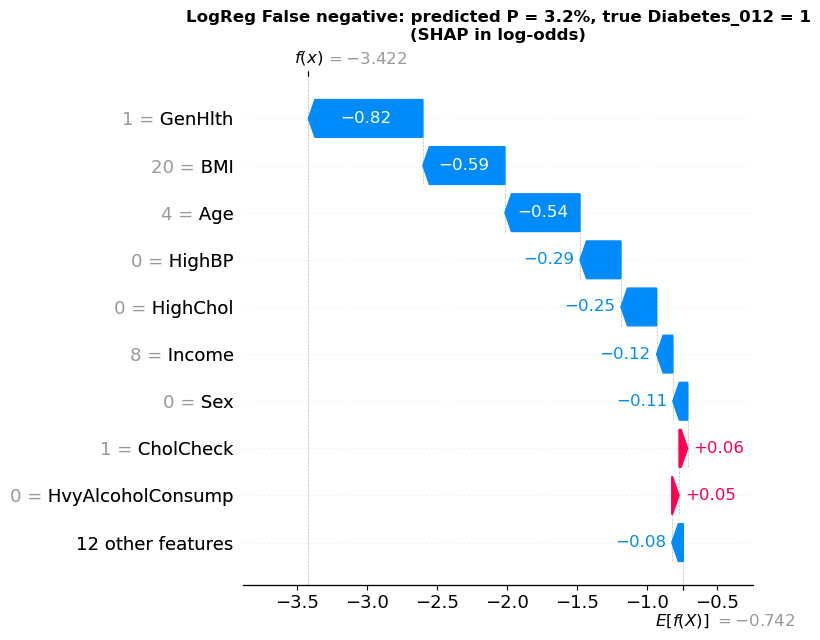

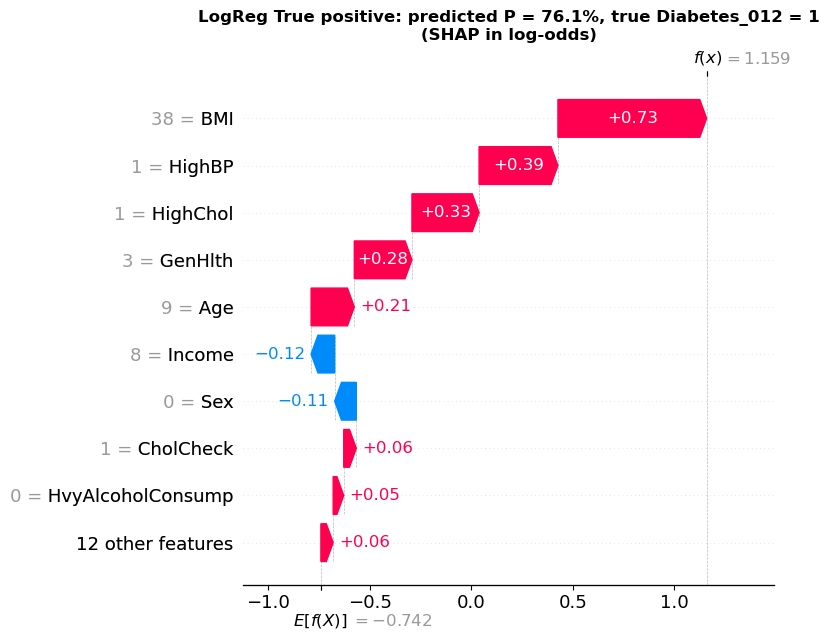

In [37]:
# ===== Local SHAP: false negative vs true positive (Logistic Regression) =====

test_proba = predict_proba(X_test_raw)[:, 1]

# People who HAVE prediabetes/diabetes, split by whether the model caught them
fn_idx = np.where((test_pred == 0) & (y_test == 1))[0]   # missed
tp_idx = np.where((test_pred == 1) & (y_test == 1))[0]   # found
print(f'People with prediabetes/diabetes in test set: {int(np.sum(y_test == 1))}')
print(f'  Found (true positives):   {len(tp_idx)}')
print(f'  Missed (false negatives): {len(fn_idx)}\n')

# False negative: the most confident miss (lowest predicted risk)
idx_fn = fn_idx[np.argmin(test_proba[fn_idx])]

# True positive: a typical hit (predicted risk closest to the median of all hits)
median_tp = np.median(test_proba[tp_idx])
idx_tp = tp_idx[np.argmin(np.abs(test_proba[tp_idx] - median_tp))]

# Feature values side by side
cases = pd.DataFrame({
    f'False negative (#{idx_fn})': X_test_raw[idx_fn],
    f'True positive (#{idx_tp})': X_test_raw[idx_tp],
}, index=FEATURE_COLS)
print(cases.to_string())

# SHAP waterfall for each case (log-odds)
for name, i in [('False negative', idx_fn), ('True positive', idx_tp)]:
    sv_i = lin_explainer.shap_values(X_test[i:i + 1])[0]
    exp_i = shap.Explanation(values=sv_i, base_values=expected_val,
                             data=X_test_raw[i], feature_names=FEATURE_COLS)
    shap.plots.waterfall(exp_i, max_display=10, show=False)
    plt.title(f'LogReg {name}: predicted P = {test_proba[i]:.1%}, true Diabetes_012 = {y012_test[i]}\n(SHAP in log-odds)',
              fontsize=12, fontweight='bold')
    plt.tight_layout()
    file_name = 'shap_' + name.lower().replace(' ', '_') + '_logreg.png'
    plt.savefig(file_name, dpi=200, bbox_inches='tight')
    plt.show()

### 10.6 Explain one chosen person

Index 50: True negative, predicted P = 6.1%, true class = No diabetes (Diabetes_012 = 0)
Baseline -0.742 + sum of SHAP -1.988 = -2.729

                      value   SHAP
Age                     4.0 -0.537
BMI                    22.0 -0.440
HighBP                  0.0 -0.293
GenHlth                 2.0 -0.267
HighChol                0.0 -0.255
Income                  8.0 -0.116
Sex                     0.0 -0.107
CholCheck               1.0  0.062
HvyAlcoholConsump       0.0  0.052
Education               6.0 -0.033
Fruits                  1.0 -0.022
HeartDiseaseorAttack    0.0 -0.016
PhysHlth                2.0  0.016
DiffWalk                0.0 -0.011
PhysActivity            1.0 -0.011
NoDocbcCost             0.0 -0.009
Veggies                 1.0 -0.004
Stroke                  0.0 -0.004
AnyHealthcare           1.0  0.004
MentHlth                0.0  0.004
Smoker                  0.0 -0.000


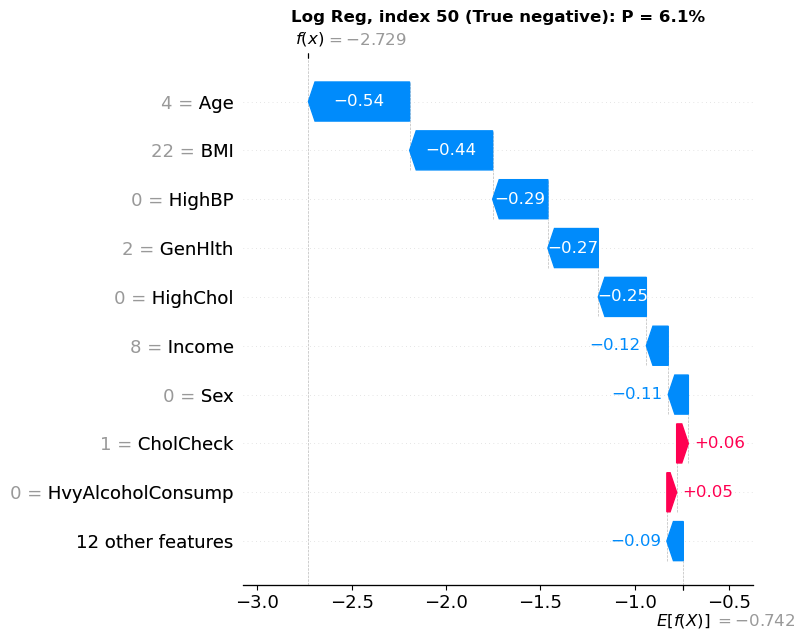

In [38]:
# Explain one chosen test person (change i to look at someone else)
i = 50
sv_i = lin_explainer.shap_values(X_test[i:i + 1])[0]     # log-odds

pred = int(test_proba[i] >= 0.5)
true = int(y_test[i])
kind = {(1, 1): 'True positive', (0, 0): 'True negative',
        (1, 0): 'False positive', (0, 1): 'False negative'}[(pred, true)]

print(f'Index {i}: {kind}, predicted P = {test_proba[i]:.1%}, '
      f'true class = {class_names[true]} (Diabetes_012 = {y012_test[i]})')
print(f'Baseline {expected_val:.3f} + sum of SHAP {sv_i.sum():+.3f} = {expected_val + sv_i.sum():.3f}\n')

shap_table = pd.DataFrame({'value': X_test_raw[i], 'SHAP': sv_i}, index=FEATURE_COLS)
print(shap_table.sort_values('SHAP', key=abs, ascending=False).round(3).to_string())

exp_i = shap.Explanation(values=sv_i, base_values=expected_val,
                         data=X_test_raw[i], feature_names=FEATURE_COLS)
shap.plots.waterfall(exp_i, max_display=10, show=False)
plt.title(f'Log Reg, index {i} ({kind}): P = {test_proba[i]:.1%}',
          fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(f'shap_index_{i}_logreg.png', dpi=200, bbox_inches='tight')
plt.show()

## 11. Latent space: PCA, t-SNE and UMAP

### 11.1 Weighted-input representation

In [39]:
LATENT_NAME = 'weighted inputs w·x (21-D)'

N_LATENT = 5000   # t-SNE and UMAP are slow on the full test set, so we use a random sample
rng_lat = np.random.default_rng(SEED)
lat_idx = rng_lat.choice(len(X_test), size=N_LATENT, replace=False)

# each standardized feature multiplied by its weight (broadcasting: (N, 21) * (21,))
H = X_test[lat_idx] * model.coef_[0]

lat_y012 = y012_test[lat_idx]     # true 3-class label of the sampled persons
lat_proba = test_proba[lat_idx]   # model's predicted probability

# check: summing the contributions + intercept gives back the model's logit
assert np.allclose(H.sum(axis=1) + model.intercept_[0], model.decision_function(X_test[lat_idx]))

print('Latent representation shape:', H.shape)
print('Classes in the sample (0, 1, 2):', np.bincount(lat_y012))

Latent representation shape: (5000, 21)
Classes in the sample (0, 1, 2): [4232   92  676]


### 11.2 Compute the embeddings

In [40]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

# --- PCA: linear projection onto the 2 directions with the most variance ---
pca = PCA(n_components=2, random_state=SEED)
emb_pca = pca.fit_transform(H)
print('PCA explained variance ratio (PC1, PC2):', pca.explained_variance_ratio_.round(3))

# --- t-SNE: non-linear, keeps local neighbourhoods ---
tsne = TSNE(n_components=2, perplexity=30, init='pca', random_state=SEED)
emb_tsne = tsne.fit_transform(H)
print('t-SNE done')

# --- UMAP: non-linear, keeps local neighbourhoods and (some) global structure ---
reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=SEED)
emb_umap = reducer.fit_transform(H)
print('UMAP done')

PCA explained variance ratio (PC1, PC2): [0.37 0.22]
t-SNE done


/Users/noahwestheimer/miniforge3/envs/dtu02451/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP done


### 11.3 Coloured by label and prediction

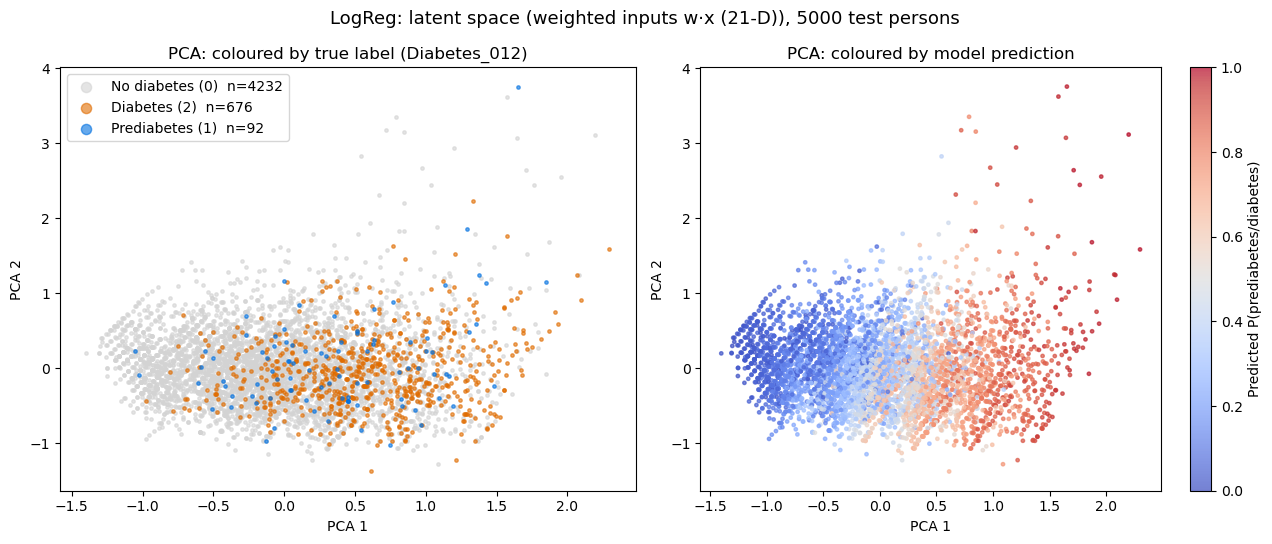

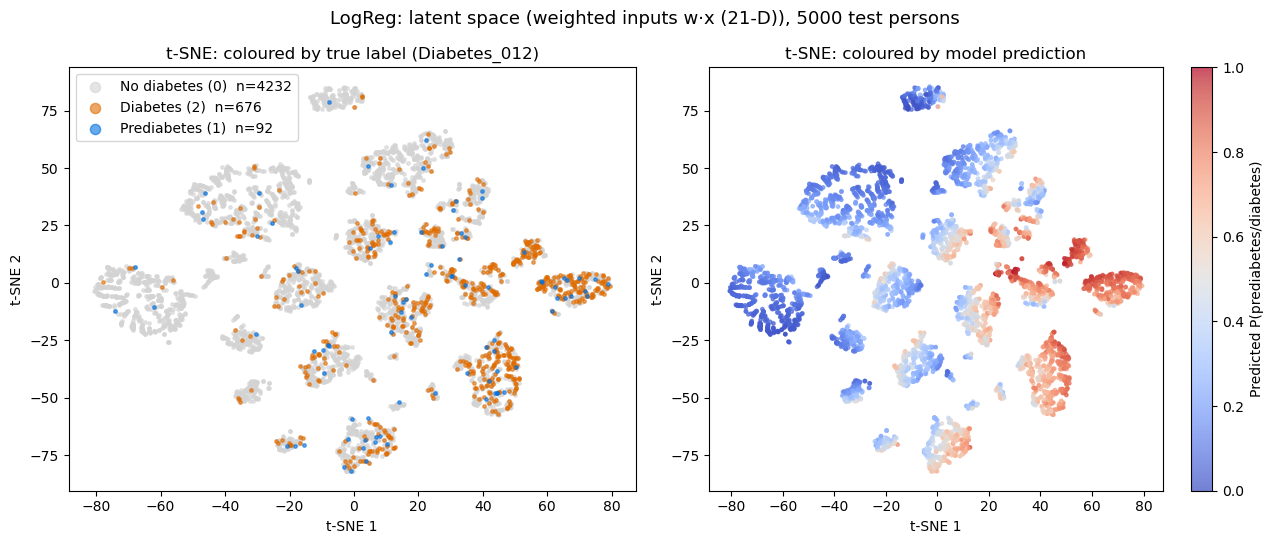

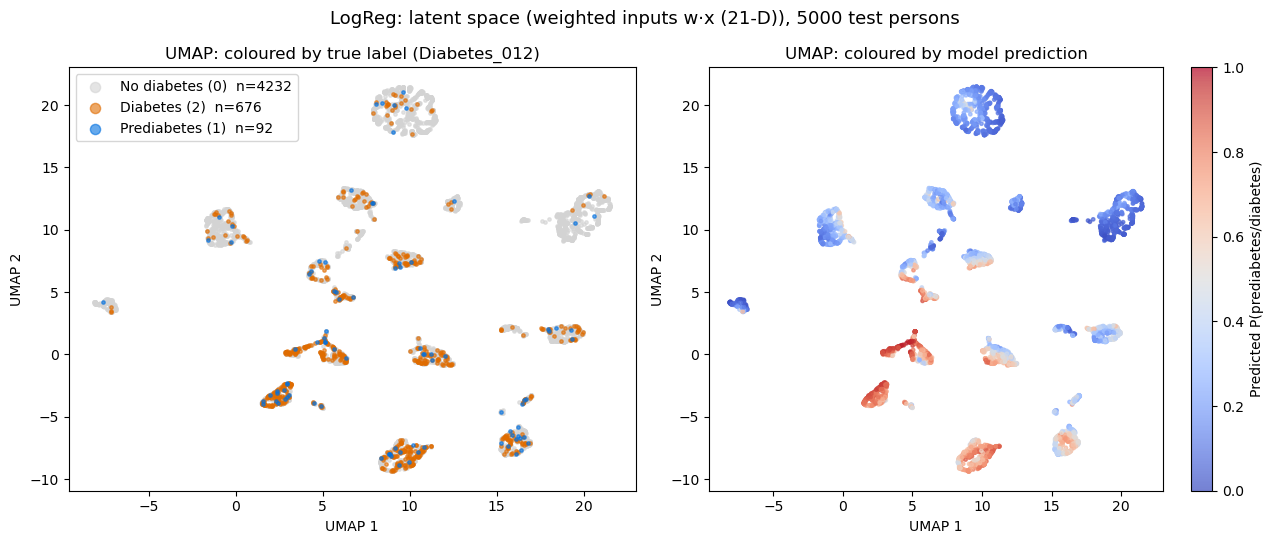

In [41]:
class_colors = {0: 'lightgray', 1: '#0070e0', 2: '#e06c00'}
class_labels = {0: 'No diabetes (0)', 1: 'Prediabetes (1)', 2: 'Diabetes (2)'}

embeddings = [(emb_pca, 'PCA'), (emb_tsne, 't-SNE'), (emb_umap, 'UMAP')]

for emb, method_name in embeddings:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

    # Left: true 3-class label. The big class is drawn first so the small classes stay visible on top.
    for c in [0, 2, 1]:
        mask = lat_y012 == c
        axes[0].scatter(emb[mask, 0], emb[mask, 1], s=6, alpha=0.6, color=class_colors[c],
                        label=f'{class_labels[c]}  n={mask.sum()}')
    axes[0].set_title(f'{method_name}: coloured by true label (Diabetes_012)')
    axes[0].legend(markerscale=3, loc='best')

    # Right: the model's predicted probability
    sc = axes[1].scatter(emb[:, 0], emb[:, 1], c=lat_proba, cmap='coolwarm', vmin=0, vmax=1, s=6, alpha=0.7)
    plt.colorbar(sc, ax=axes[1], label='Predicted P(prediabetes/diabetes)')
    axes[1].set_title(f'{method_name}: coloured by model prediction')

    for ax in axes:
        ax.set_xlabel(f'{method_name} 1')
        ax.set_ylabel(f'{method_name} 2')

    fig.suptitle(f'{MODEL_TAG}: latent space ({LATENT_NAME}), {N_LATENT} test persons', fontsize=13)
    plt.tight_layout()
    plt.savefig(f'latent_{method_name.lower().replace("-", "")}_{MODEL_TAG.lower().replace(" ", "")}.png', dpi=200)
    plt.show()

### 11.4 Concepts in the latent space

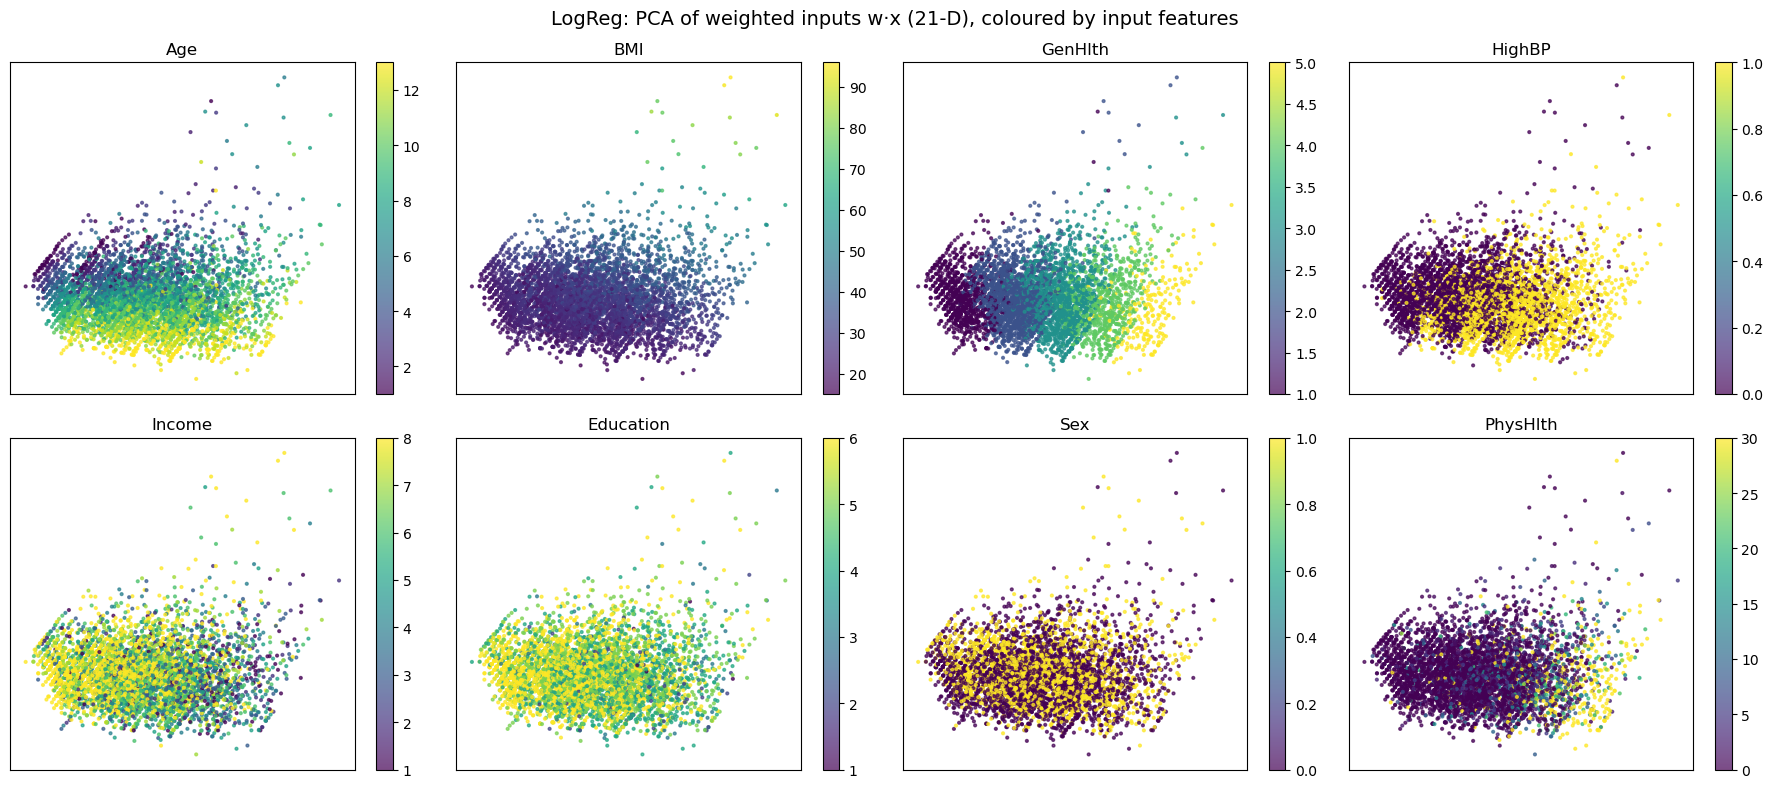

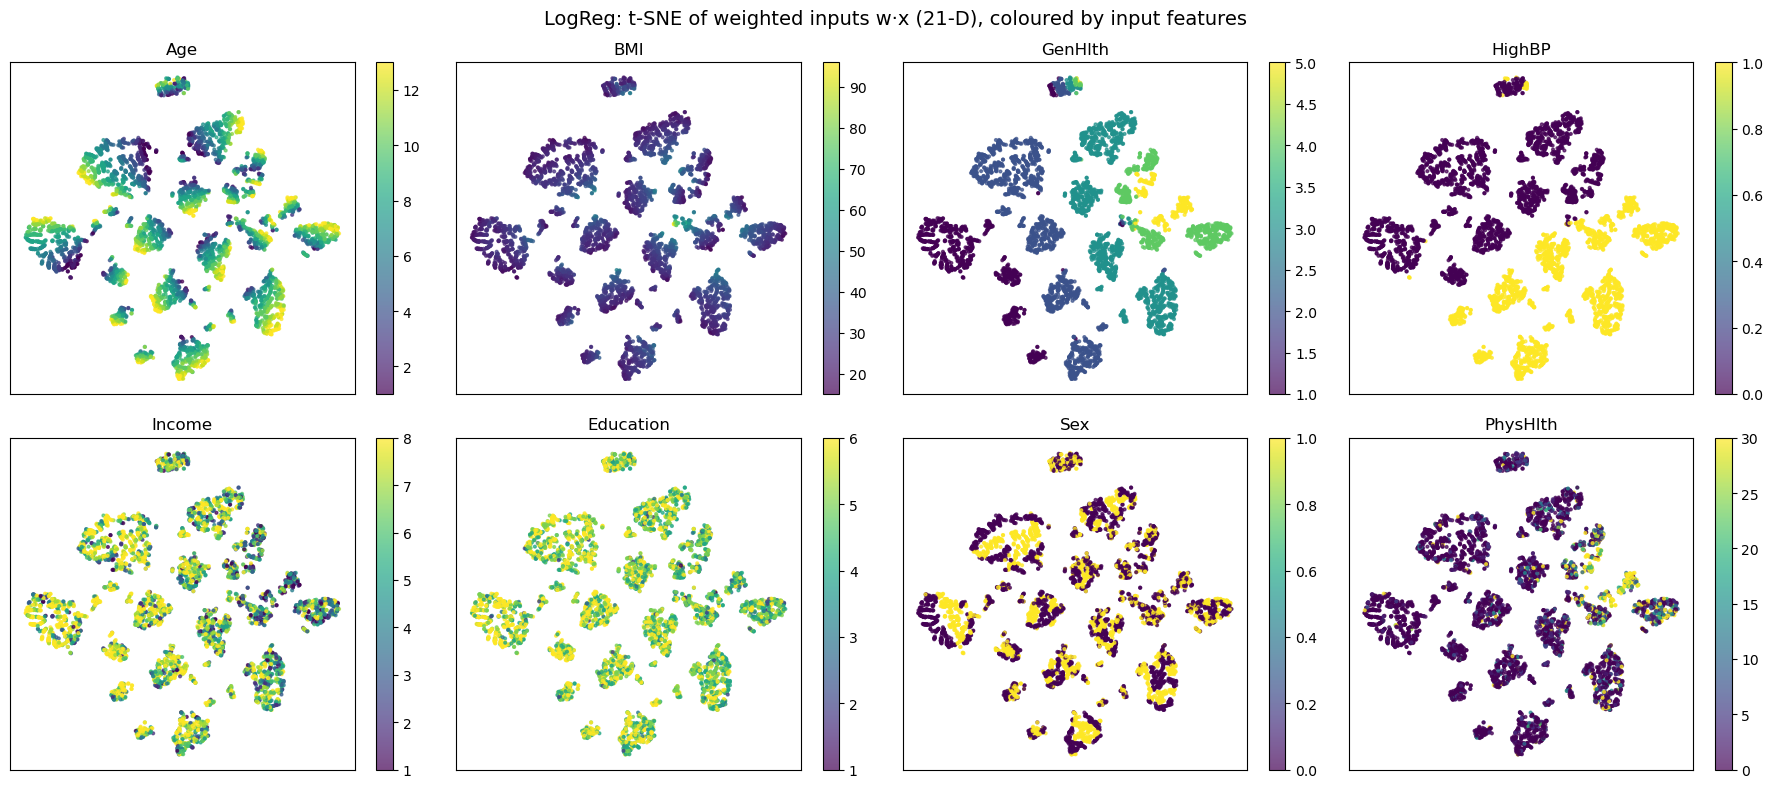

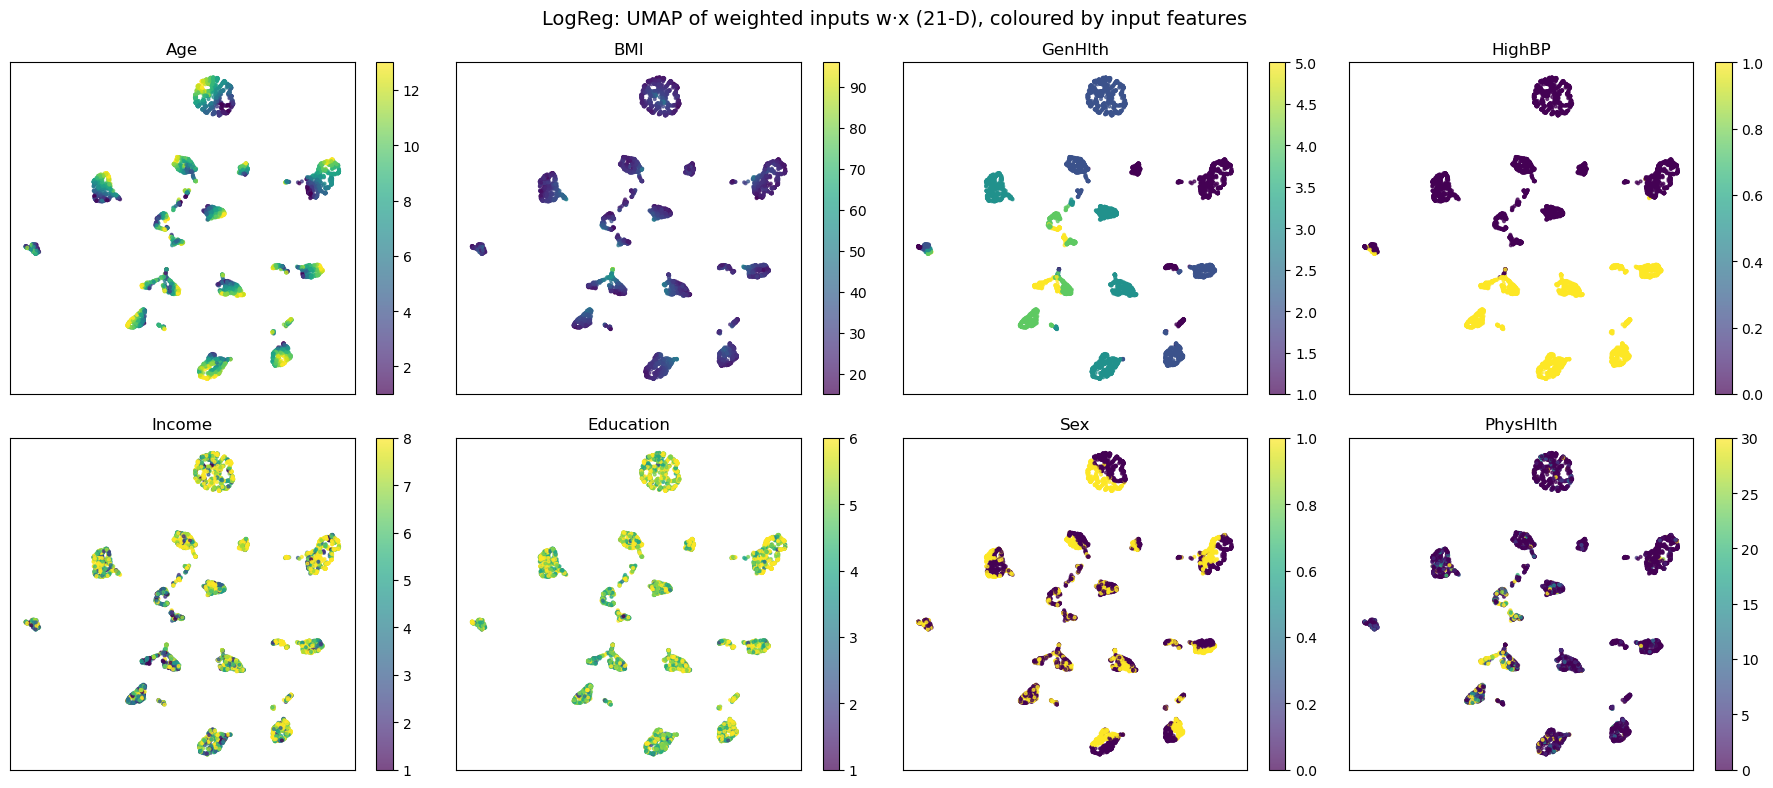

In [42]:
concept_features = ['Age', 'BMI', 'GenHlth', 'HighBP', 'Income', 'Education', 'Sex', 'PhysHlth']
lat_raw = X_test_raw[lat_idx]

for emb, method_name in embeddings:
    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    for ax, feat in zip(axes.ravel(), concept_features):
        values = lat_raw[:, FEATURE_COLS.index(feat)]
        sc = ax.scatter(emb[:, 0], emb[:, 1], c=values, cmap='viridis', s=4, alpha=0.7)
        plt.colorbar(sc, ax=ax)
        ax.set_title(feat)
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(f'{MODEL_TAG}: {method_name} of {LATENT_NAME}, coloured by input features', fontsize=14)
    plt.tight_layout()
    plt.savefig(f'latent_concepts_{method_name.lower().replace("-", "")}_{MODEL_TAG.lower().replace(" ", "")}.png', dpi=200)
    plt.show()

## 12. Removing Income: effect on performance

### 12.1 Data without Income

In [43]:
# Position of the Income column in the original feature list
inc_idx = FEATURE_COLS.index('Income')
FEATURE_COLS_NI = [c for c in FEATURE_COLS if c != 'Income']

# Remove the Income column from the standardized data (same rows and same split as before).
# Every column is standardized on its own, so deleting a standardized column gives
# exactly the same numbers as standardizing the 20 remaining columns again.
X_train_ni = np.delete(X_train, inc_idx, axis=1)
X_val_ni = np.delete(X_val, inc_idx, axis=1)
X_test_ni = np.delete(X_test, inc_idx, axis=1)

# Keep each person's income on the side.
# It is NOT given to the model, it is only used to choose concept examples later.
income_train = X_train_raw[:, inc_idx]
income_test = X_test_raw[:, inc_idx]

print('Features used by the new model:', len(FEATURE_COLS_NI))
print('Train:', X_train_ni.shape, ' Val:', X_val_ni.shape, ' Test:', X_test_ni.shape)

Features used by the new model: 20
Train: (162355, 20)  Val: (40589, 20)  Test: (50736, 20)


### 12.2 Retrain without Income

In [44]:
model_ni = LogisticRegression(solver='lbfgs', max_iter=1, warm_start=True,
                              C=C_reg, class_weight=class_weights, random_state=seed)

train_losses_ni = []
val_losses_ni = []

best_val_loss_ni = np.inf
best_coef_ni = None
best_intercept_ni = None
best_epoch_ni = 0
epochs_without_improvement = 0

for epoch in range(max_epochs):
    # one epoch of training
    model_ni.fit(X_train_ni, y_train)

    # weighted loss on train and validation
    train_loss = log_loss(y_train, model_ni.predict_proba(X_train_ni), sample_weight=sw_train)
    val_loss = log_loss(y_val, model_ni.predict_proba(X_val_ni), sample_weight=sw_val)
    train_losses_ni.append(train_loss)
    val_losses_ni.append(val_loss)

    # early stopping check
    if val_loss < best_val_loss_ni - min_delta:
        best_val_loss_ni = val_loss
        best_coef_ni = model_ni.coef_.copy()
        best_intercept_ni = model_ni.intercept_.copy()
        best_epoch_ni = epoch
        epochs_without_improvement = 0
    else:
        epochs_without_improvement = epochs_without_improvement + 1

    if epochs_without_improvement >= patience:
        print(f"Early stopping at epoch {epoch}")
        break

# restore the best weights
model_ni.coef_ = best_coef_ni
model_ni.intercept_ = best_intercept_ni

print(f"Best epoch: {best_epoch_ni}, val loss: {best_val_loss_ni:.4f}")

Early stopping at epoch 16
Best epoch: 11, val loss: 0.5194


### 12.3 Performance with vs without Income

In [45]:
proba_full = model.predict_proba(X_test)[:, 1]        # original model (21 features)
proba_ni = model_ni.predict_proba(X_test_ni)[:, 1]    # new model (20 features)

rows = []
for name, p in [('With Income (original)', proba_full), ('Without Income', proba_ni)]:
    pred = (p >= 0.5).astype(int)
    rows.append({
        'model': name,
        'accuracy': np.mean(pred == y_test),
        'balanced acc': balanced_accuracy_score(y_test, pred),
        'recall (pos)': np.mean(pred[y_test == 1] == 1),
        'ROC-AUC': roc_auc_score(y_test, p),
        'PR-AUC': average_precision_score(y_test, p),
    })
print(pd.DataFrame(rows).round(3).to_string(index=False))

                 model  accuracy  balanced acc  recall (pos)  ROC-AUC  PR-AUC
With Income (original)     0.731         0.743         0.761    0.818   0.433
        Without Income     0.730         0.742         0.760    0.817   0.432
